# 11 — Turn intuition into a research test

**Question:** How do we distinguish an interesting example from reproducible evidence?

**By the end:** define a hypothesis, preserve dependent observations, summarize
effect size, inspect local resampling, and refuse unsupported market-level confidence.
**Time:** 35–45 minutes. **Inputs:** causal features and observed forward midpoint
movement. The current sample contains one independent market window.

In [1]:
import sys
from pathlib import Path

for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.advanced import (
    clustered_effect,
    feature_dataset,
    local_block_means,
)
from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    finish_plot,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Write the hypothesis before searching thresholds

**Teaching hypothesis:** at eligible decision times, a top-level imbalance above
+0.25 is associated with a larger next-five-second Up midpoint movement than an
imbalance below −0.25.

The threshold, horizon, freshness filters, handling of snapshots and outcome
definition are fixed for this lesson. We examine an association, not causality or
a claim that the imbalance predicts terminal Up. The equity-market work by
[Cont, Kukanov and Stoikov](https://arxiv.org/abs/1011.6402) motivates questions about
book events; it does not validate our PM hypothesis.

In [2]:
study = BookStudy(sample)
data = feature_dataset(sample, study)
display(
    pd.Series(
        {
            "clock_grid_rows": len(data),
            "observed_forward_targets": int(data.forward_move_cents.notna().sum()),
            "complete_feature_and_target_rows": int(data.research_row_eligible.sum()),
            "independent_market_windows": data.market_id.nunique(),
        }
    )
)
diagnostic = data[data.forward_move_cents.notna()].copy()
diagnostic["imbalance_group"] = np.select(
    [diagnostic.imbalance >= 0.25, diagnostic.imbalance <= -0.25],
    ["High (+)", "Low (−)"],
    default="Middle",
)
summary = diagnostic.groupby("imbalance_group").forward_move_cents.agg(
    ["count", "mean", "median", "std"]
)
display(summary)

clock_grid_rows                     300
observed_forward_targets            122
complete_feature_and_target_rows    109
independent_market_windows            1
dtype: int64

,count,mean,median,std
imbalance_group,,,,
High (+),42,1.345238,1.0,1.617315
Low (−),57,0.087719,0.5,3.457811
Middle,23,1.000000,1.0,3.089572


## 2. Plot effect size before celebrating a score

The group means have units: cents per share of later midpoint movement. They are
not realized cash profit. Spread, fees, execution and adverse selection are absent.
Group differences can be produced by time trends, volatility regimes or chance.

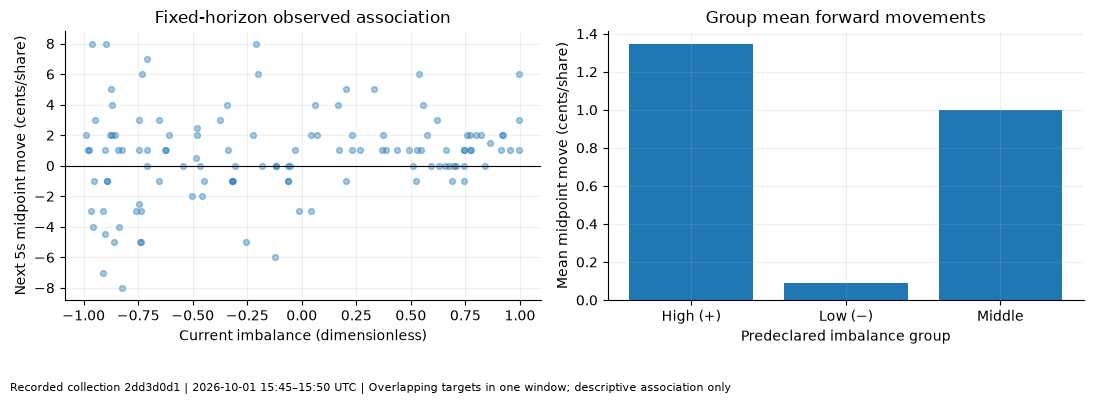

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(diagnostic.imbalance, diagnostic.forward_move_cents, alpha=0.4, s=18)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(
    title="Fixed-horizon observed association",
    xlabel="Current imbalance (dimensionless)",
    ylabel="Next 5s midpoint move (cents/share)",
)
axes[1].bar(summary.index, summary["mean"])
axes[1].set(
    title="Group mean forward movements",
    xlabel="Predeclared imbalance group",
    ylabel="Mean midpoint move (cents/share)",
)
finish_plot(fig, sample, "Overlapping targets in one window; descriptive association only")

## 3. Neighboring targets reuse the same future observations

A target at second 50 uses prices through second 55. A target at second 51 uses
prices through second 56. They overlap; collecting many such rows does not create
many independent experiments. For a later train/test split, purge labels and
feature lookbacks that cross the boundary.

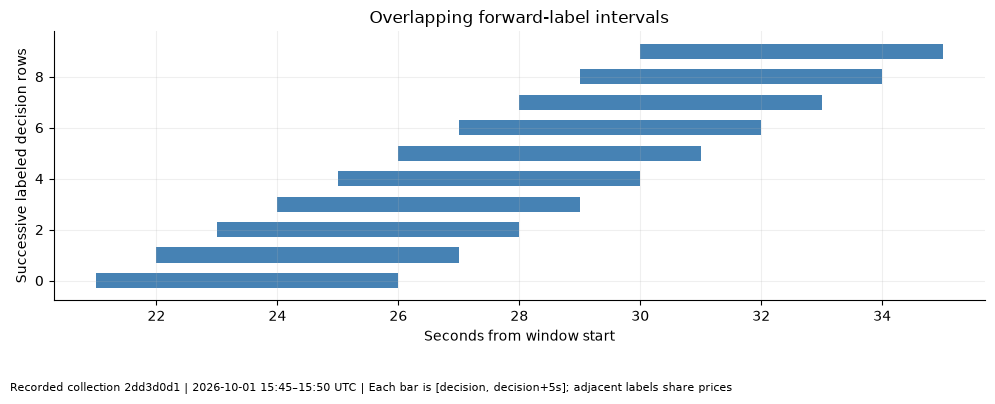

In [4]:
examples = data[data.research_row_eligible].head(10)
fig, ax = plt.subplots()
origin = pd.Timestamp(sample.start, tz="UTC")
for i, row in enumerate(examples.itertuples()):
    start = (row.time - origin).total_seconds()
    end = (row.label_end - origin).total_seconds()
    ax.broken_barh([(start, end - start)], (i - 0.3, 0.6), facecolors="steelblue")
ax.set(
    title="Overlapping forward-label intervals",
    xlabel="Seconds from window start",
    ylabel="Successive labeled decision rows",
)
finish_plot(fig, sample, "Each bar is [decision, decision+5s]; adjacent labels share prices")

## 4. Local block resampling illustrates dependence, not new-market uncertainty

We retain the full one-second clock, including NaNs. Consecutive blocks crossing
missing observations are rejected. Resampling blocks illustrates how conclusions
depend on assumed local dependence. It cannot provide a market-wide confidence
interval from one trending window, and block resampling also has stationarity
assumptions that may fail near expiry.

,block_length_s,illustrative_resampled_mean_cents,illustrative_2.5pct_cents,illustrative_97.5pct_cents
0,1,0.688311,0.122541,1.209016
1,5,0.636280,-0.206100,1.499100
2,10,0.482308,-0.394327,1.365577


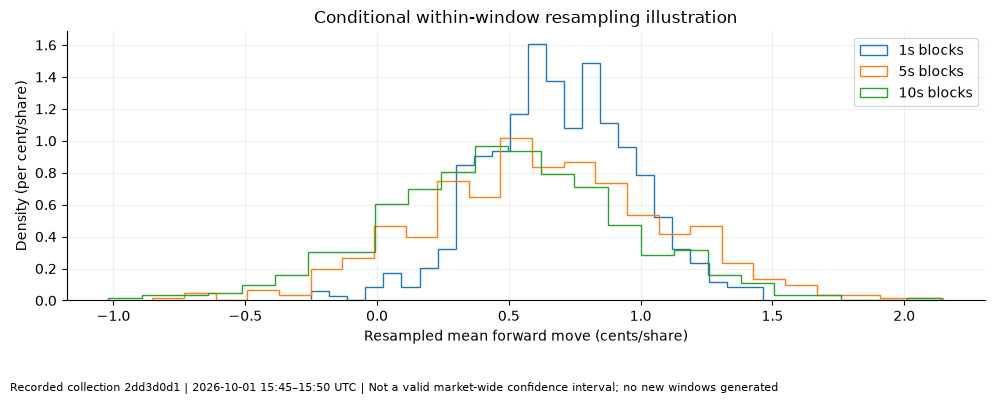

In [5]:
regular_target = data.set_index("time").forward_move_cents
block_samples = {}
for block_length in [1, 5, 10]:
    block_samples[block_length] = local_block_means(regular_target, block_length, seed=7)
display(
    pd.DataFrame(
        [
            {
                "block_length_s": length,
                "illustrative_resampled_mean_cents": values.mean(),
                "illustrative_2.5pct_cents": np.quantile(values, 0.025),
                "illustrative_97.5pct_cents": np.quantile(values, 0.975),
            }
            for length, values in block_samples.items()
        ]
    )
)
fig, ax = plt.subplots()
for length, values in block_samples.items():
    ax.hist(values, bins=25, density=True, histtype="step", label=f"{length}s blocks")
ax.set(
    title="Conditional within-window resampling illustration",
    xlabel="Resampled mean forward move (cents/share)",
    ylabel="Density (per cent/share)",
)
ax.legend()
finish_plot(fig, sample, "Not a valid market-wide confidence interval; no new windows generated")

## 5. The proper market-level uncertainty gate

For several windows, a cluster resample draws entire market IDs, preserving each
window's internal dependence. Adjacent windows may still be dependent; larger
calendar blocks and regime coverage can be needed. Two windows merely allow the
mechanics to run, not a reliable inference.

With one window we report the descriptive effect but deliberately decline an
independent-window interval. This is a result, not an invitation to count messages
as independent samples.

In [6]:
assessment = clustered_effect(data)
display(pd.Series(assessment, name="High-minus-low imbalance diagnostic"))
assert assessment["market_count"] != 1 or assessment["interval"] is None

effect_cents                            1.257519
market_count                                   1
interval                                    None
status          insufficient_independent_windows
Name: High-minus-low imbalance diagnostic, dtype: object

## 6. A small research contract for the next dataset

Before gathering more results, write down: date range and selection policy,
eligible observations, horizon and thresholds, primary metric, cost assumptions,
chronological holdout, uncertainty method, and what would reject the hypothesis.
Record unsuccessful variants too. Trying many thresholds and reporting only the
best one selects noise.

In [7]:
research_contract = {
    "question": "Does standing imbalance precede midpoint movement?",
    "target": "next 5s observed Up midpoint change, not terminal outcome",
    "threshold": "high >= +.25, low <= -.25, fixed before this diagnostic",
    "eligibility": "fresh two-sided quotes, causal BTC features, recorded gaps excluded",
    "primary_effect": "high-minus-low mean movement in cents/share",
    "cost_evaluation": "separate execution scenarios; midpoint movement is not PnL",
    "holdout": "later whole markets; purge overlapping label/lookback intervals",
    "current_decision": "insufficient independent windows for a predictive claim",
}
display(pd.Series(research_contract))

question            Does standing imbalance precede midpoint movem...
target              next 5s observed Up midpoint change, not termi...
threshold           high >= +.25, low <= -.25, fixed before this d...
eligibility         fresh two-sided quotes, causal BTC features, r...
primary_effect            high-minus-low mean movement in cents/share
cost_evaluation     separate execution scenarios; midpoint movemen...
holdout             later whole markets; purge overlapping label/l...
current_decision    insufficient independent windows for a predict...
dtype: str

## Exercise — explain a narrow interval

Suppose the one-second bootstrap yields a narrow interval. Why is it not strong
evidence? What happens if you remove missing timestamps before forming blocks?

**Suggested answer:** it conditions on one path and can underestimate dependence
and regime uncertainty. Dropping missing rows creates fake adjacency across gaps.
Even a genuine effect must survive later windows and execution costs.

**Research use:** this creates a repeatable question and honest stopping criteria.
**Next:** [12 — First ML dataset](12_first_ml_dataset.ipynb).